In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTE
from sklearn.metrics import roc_auc_score, roc_curve, ConfusionMatrixDisplay

In [2]:
# Cargar datos (ajusta el nombre del archivo si es diferente)
df = pd.read_csv('telecom_churn.csv')

# 1. Convertir TotalCharges a numérico (forzando errores a nulos)
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

# 2. Gestionar valores nulos imputando la mediana
df['TotalCharges'] = df['TotalCharges'].fillna(df['TotalCharges'].median())

# Eliminar columna ID si existe, ya que no aporta a la predicción
if 'customerID' in df.columns:
    df = df.drop(columns=['customerID'])

# 3. Preprocesar características categóricas con OneHotEncoder (get_dummies)
df_encoded = pd.get_dummies(df, drop_first=True)

# Visualizar las primeras filas preparadas
display(df_encoded.head())

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,MultipleLines_Yes,...,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check,Churn_Yes
0,0,1,29.85,29.85,False,True,False,False,True,False,...,False,False,False,False,False,True,False,True,False,False
1,0,34,56.95,1889.50,True,False,False,True,False,False,...,False,False,False,True,False,False,False,False,True,False
2,0,2,53.85,108.15,True,False,False,True,False,False,...,False,False,False,False,False,True,False,False,True,True
3,0,45,42.30,1840.75,True,False,False,False,True,False,...,False,False,False,True,False,False,False,False,False,False
4,0,2,70.70,151.65,False,False,False,True,False,False,...,False,False,False,False,False,True,False,True,False,True


In [3]:
# Definir X (características) e y (objetivo). Asumimos que la columna objetivo es 'Churn_Yes'
target_col = 'Churn_Yes' if 'Churn_Yes' in df_encoded.columns else 'Churn'
X = df_encoded.drop(columns=[target_col])
y = df_encoded[target_col]

# Dividir en entrenamiento (80%) y prueba (20%)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Equilibrar las clases objetivo de entrenamiento usando SMOTE
smote = SMOTE(random_state=42)
X_train_res, y_train_res = smote.fit_resample(X_train, y_train)

print(f"Distribución original:\n{y_train.value_counts()}")
print(f"Distribución equilibrada (SMOTE):\n{y_train_res.value_counts()}")

Distribución original:
Churn_Yes
False    4139
True     1495
Name: count, dtype: int64
Distribución equilibrada (SMOTE):
Churn_Yes
False    4139
True     4139
Name: count, dtype: int64


In [4]:
# Entrenar Random Forest
rf_model = RandomForestClassifier(random_state=42, n_jobs=-1)
rf_model.fit(X_train_res, y_train_res)

# Entrenar XGBoost
xgb_model = XGBClassifier(random_state=42, eval_metric='logloss', use_label_encoder=False)
xgb_model.fit(X_train_res, y_train_res)

print("Modelos entrenados exitosamente con datos equilibrados.")

c:\Users\sarah\anaconda3\Lib\site-packages\xgboost\training.py:200: UserWarning: [16:59:51] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


Modelos entrenados exitosamente con datos equilibrados.


ROC-AUC Random Forest: 0.8186
ROC-AUC XGBoost: 0.8181


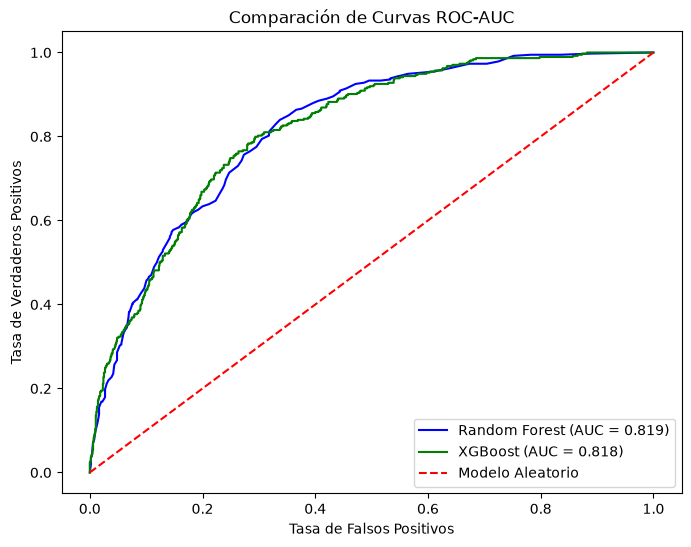

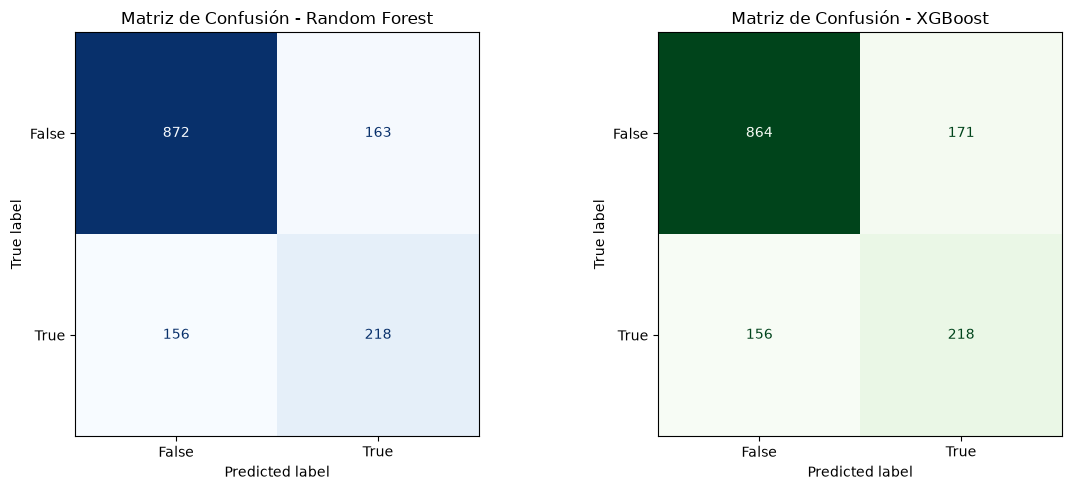

In [5]:
# Obtener probabilidades de predicción
rf_probs = rf_model.predict_proba(X_test)[:, 1]
xgb_probs = xgb_model.predict_proba(X_test)[:, 1]

# Calcular ROC-AUC (Debe superar el 80%)
rf_auc = roc_auc_score(y_test, rf_probs)
xgb_auc = roc_auc_score(y_test, xgb_probs)

print(f"ROC-AUC Random Forest: {rf_auc:.4f}")
print(f"ROC-AUC XGBoost: {xgb_auc:.4f}")

# 1. Trazar Curvas ROC-AUC
plt.figure(figsize=(8, 6))
fpr_rf, tpr_rf, _ = roc_curve(y_test, rf_probs)
fpr_xgb, tpr_xgb, _ = roc_curve(y_test, xgb_probs)

plt.plot(fpr_rf, tpr_rf, label=f'Random Forest (AUC = {rf_auc:.3f})', color='blue')
plt.plot(fpr_xgb, tpr_xgb, label=f'XGBoost (AUC = {xgb_auc:.3f})', color='green')
plt.plot([0, 1], [0, 1], 'r--', label='Modelo Aleatorio')
plt.xlabel('Tasa de Falsos Positivos')
plt.ylabel('Tasa de Verdaderos Positivos')
plt.title('Comparación de Curvas ROC-AUC')
plt.legend()
plt.show()

# 2. Matrices de Confusión
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
ConfusionMatrixDisplay.from_estimator(rf_model, X_test, y_test, ax=ax[0], cmap='Blues', colorbar=False)
ax[0].set_title('Matriz de Confusión - Random Forest')
ConfusionMatrixDisplay.from_estimator(xgb_model, X_test, y_test, ax=ax[1], cmap='Greens', colorbar=False)
ax[1].set_title('Matriz de Confusión - XGBoost')
plt.tight_layout()
plt.show()

C:\Users\sarah\AppData\Local\Temp\ipykernel_22016\785543121.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=importances[indices], y=features, palette='magma')


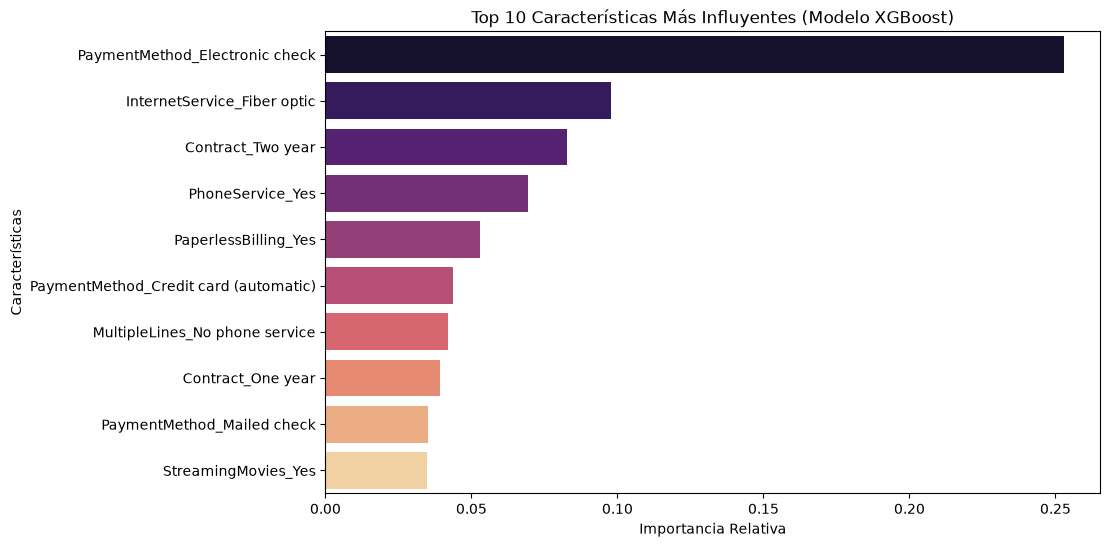

In [6]:
# Extraer la importancia de características del mejor modelo (generalmente XGBoost)
importances = xgb_model.feature_importances_
indices = np.argsort(importances)[::-1][:10] # Top 10
features = X.columns[indices]

# Trazar el gráfico de barras
plt.figure(figsize=(10, 6))
sns.barplot(x=importances[indices], y=features, palette='magma')
plt.title('Top 10 Características Más Influyentes (Modelo XGBoost)')
plt.xlabel('Importancia Relativa')
plt.ylabel('Características')
plt.show()
